<a href="https://colab.research.google.com/github/MysaniThiya/Agentra-RajarataUniversityOfSriLanka/blob/feature%2Femail-analysis/email_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
!git --version

git version 2.43.0


In [8]:
!git clone https://github.com/MysaniThiya/Agentra-RajarataUniversityOfSriLanka.git


fatal: destination path 'Agentra-RajarataUniversityOfSriLanka' already exists and is not an empty directory.


In [9]:
%cd Agentra-RajarataUniversityOfSriLanka


/content/Agentra-RajarataUniversityOfSriLanka


In [10]:
!ls


Agentra-RajarataUniversityOfSriLanka  project		README.md
docs				      project-demo.mp4


In [11]:
!git fetch origin

In [12]:
!git branch -a

* main
  remotes/origin/Fasna
  remotes/origin/HEAD -> origin/main
  remotes/origin/feature/email-analysis
  remotes/origin/main
  remotes/origin/url-analysis-agent


In [13]:
!git checkout -b feature/email-analysis origin/feature/email-analysis

branch 'feature/email-analysis' set up to track 'origin/feature/email-analysis'.
Switched to a new branch 'feature/email-analysis'


In [14]:
!git branch


* feature/email-analysis
  main


In [15]:
import os

os.makedirs("datasets", exist_ok=True)
os.makedirs("notebooks", exist_ok=True)
os.makedirs("models", exist_ok=True)

In [16]:
!pip install -q pandas numpy scikit-learn matplotlib seaborn joblib datasets

In [17]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [18]:
from datasets import load_dataset

dataset_url = (
    "https://huggingface.co/datasets/"
    "locuoco/the-biggest-spam-ham-phish-email-dataset-300000/"
    "resolve/main/df.csv"
)

# Load the CSV as a streaming dataset
email_stream = load_dataset(
    "csv",
    data_files=dataset_url,
    split="train",
    streaming=True
)

# Shuffle and select 60,000 records for the first experiment
email_stream = email_stream.shuffle(
    seed=42,
    buffer_size=10000
)

records = list(email_stream.take(60000))

# Convert records into a DataFrame
df = pd.DataFrame(records)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (60000, 2)


,label,text
0,0,daren i know it ' s first of the month but the...
1,0,jodi chris can set up a conference call with m...
2,0,the recruiting season has officially begun the...
3,0,attached is a memo summarizing policy changes ...
4,0,please let me know if you are available for a ...


In [19]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nLabel distribution:")
print(df["label"].value_counts().sort_index())

print("\nEmail examples:")
display(df[["text", "label"]].head(10))

Column names:
['label', 'text']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60000 entries, 0 to 59999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   label   60000 non-null  int64 
 1   text    60000 non-null  object
dtypes: int64(1), object(1)
memory usage: 937.6+ KB

Label distribution:
label
0    32329
2    27671
Name: count, dtype: int64

Email examples:


,text,label
0,daren i know it ' s first of the month but the...,0
1,jodi chris can set up a conference call with m...,0
2,the recruiting season has officially begun the...,0
3,attached is a memo summarizing policy changes ...,0
4,please let me know if you are available for a ...,0
5,louise effective escapenumber escapenumber esc...,0
6,new power plant added to pnm system pnm public...,0
7,iv friends i spoken with most of you over the ...,0
8,sheila changes to the manual list for north am...,0
9,i also have an opportunity for a manager top c...,0


In [20]:
label_mapping = {
    0: "Ham / Safe",
    1: "Phishing / Malicious",
    2: "Spam / Provisional Suspicious"
}

print("Original label distribution:")

for label, count in df["label"].value_counts().sort_index().items():
    print(label_mapping.get(int(label), "Unknown"), ":", count)

Original label distribution:
Ham / Safe : 32329
Spam / Provisional Suspicious : 27671


In [21]:
from datasets import load_dataset
from collections import Counter

dataset_url = (
    "https://huggingface.co/datasets/"
    "locuoco/the-biggest-spam-ham-phish-email-dataset-300000/"
    "resolve/main/df.csv"
)

# Load the complete dataset as a stream
full_stream = load_dataset(
    "csv",
    data_files=dataset_url,
    split="train",
    streaming=True
)

# Count every original label
label_counts = Counter()

for row in full_stream:
    label_counts[row["label"]] += 1

print("Complete dataset label distribution:")

for label, count in sorted(label_counts.items()):
    print(f"Label {label}: {count:,} emails")

Complete dataset label distribution:
Label 0: 168,455 emails
Label 1: 42,845 emails
Label 2: 154,148 emails


In [22]:

from datasets import load_dataset
from collections import defaultdict
import pandas as pd

dataset_url = (
    "https://huggingface.co/datasets/"
    "locuoco/the-biggest-spam-ham-phish-email-dataset-300000/"
    "resolve/main/df.csv"
)

# Load the dataset as a stream
stream = load_dataset(
    "csv",
    data_files=dataset_url,
    split="train",
    streaming=True
)

# Store up to 15,000 emails from each class
samples = defaultdict(list)

MAX_PER_CLASS = 15000

for row in stream:
    label = int(row["label"])

    if label in [0, 1, 2]:
        if len(samples[label]) < MAX_PER_CLASS:
            samples[label].append({
                "text": row["text"],
                "label": label
            })

    # Stop when all three classes have 15,000 emails
    if all(len(samples[i]) >= MAX_PER_CLASS for i in [0, 1, 2]):
        break

# Create a balanced DataFrame
balanced_df = pd.DataFrame(
    [item for label in [0, 1, 2] for item in samples[label]]
)

# Shuffle the dataset
balanced_df = balanced_df.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("Balanced dataset shape:", balanced_df.shape)

print("\nClass distribution:")
print(balanced_df["label"].value_counts().sort_index())

print("\nSample emails:")
display(balanced_df.head())


Balanced dataset shape: (45000, 2)

Class distribution:
label
0    15000
1    15000
2    15000
Name: count, dtype: int64

Sample emails:


,text,label
0,downloadable software http cabins jetlow com a...,2
1,tanya fyi this is the meeting you will be atte...,0
2,dear user welcome to the world of filehunter a...,2
3,louise this draft is very preliminary we have ...,0
4,b hf v bescapenumber bescapenumber nhkl w n h...,2


In [23]:

# STEP 1: Dataset quality checking

import pandas as pd

# Create a copy of the balanced dataset
df = balanced_df.copy()

# 1. Check missing values
print("Missing values:")
print(df.isnull().sum())

# 2. Check empty email texts
empty_texts = df["text"].astype(str).str.strip().eq("").sum()
print("\nEmpty email texts:", empty_texts)

# 3. Check exact duplicate records
duplicate_rows = df.duplicated().sum()
print("Duplicate records:", duplicate_rows)

# 4. Check duplicate email texts
duplicate_texts = df["text"].duplicated().sum()
print("Duplicate email texts:", duplicate_texts)

# 5. Check whether identical texts have conflicting labels
label_counts_per_text = df.groupby("text")["label"].nunique()
conflicting_texts = (label_counts_per_text > 1).sum()

print("Emails with conflicting labels:", conflicting_texts)

# 6. Check email text lengths
df["text_length"] = df["text"].astype(str).apply(len)

print("\nEmail text length statistics:")
print(df["text_length"].describe())

# 7. Display class distribution
print("\nClass distribution:")
print(df["label"].value_counts().sort_index())


Missing values:
text     0
label    0
dtype: int64

Empty email texts: 1
Duplicate records: 0
Duplicate email texts: 1
Emails with conflicting labels: 1

Email text length statistics:
count     45000.000000
mean       1415.320378
std        6861.123090
min           1.000000
25%         308.000000
50%         630.000000
75%        1468.000000
max      916044.000000
Name: text_length, dtype: float64

Class distribution:
label
0    15000
1    15000
2    15000
Name: count, dtype: int64


In [24]:

# STEP 2: Investigate problematic email records

# Find empty emails
empty_rows = df[
    df["text"].astype(str).str.strip().eq("")
]

print("EMPTY EMAIL RECORDS:")
display(empty_rows)

# Find duplicate email texts
duplicate_rows = df[
    df["text"].duplicated(keep=False)
].sort_values("text")

print("\nDUPLICATE EMAIL RECORDS:")
display(duplicate_rows[["label", "text"]])

# Find conflicting labels
conflicting_texts = (
    df.groupby("text")["label"]
    .nunique()
)

conflicting_texts = conflicting_texts[
    conflicting_texts > 1
].index

conflict_records = df[
    df["text"].isin(conflicting_texts)
]

print("\nCONFLICTING LABEL RECORDS:")
display(conflict_records[["label", "text"]])

# Find unusually long emails
long_emails = df[
    df["text"].str.len() > 20000
]

print("\nEMAILS LONGER THAN 20,000 CHARACTERS:")
print("Number of long emails:", len(long_emails))

display(
    long_emails[["label", "text_length"]].head(10)
)


EMPTY EMAIL RECORDS:


,text,label,text_length
43489,,1,1



DUPLICATE EMAIL RECORDS:


,label,text
3868,0,unsubscribe
7954,2,unsubscribe



CONFLICTING LABEL RECORDS:


,label,text
3868,0,unsubscribe
7954,2,unsubscribe



EMAILS LONGER THAN 20,000 CHARACTERS:
Number of long emails: 114


,label,text_length
214,0,21520
320,0,21702
1603,0,139890
1967,1,22726
2532,0,32943
2737,0,37819
2861,0,73326
3614,0,89609
3884,0,30030
3960,0,75155


In [25]:

# STEP 3: Final dataset cleaning

# Keep a copy of the original dataset
cleaned_df = df[["text", "label"]].copy()

# 1. Remove empty email texts
cleaned_df = cleaned_df[
    cleaned_df["text"].notna() &
    cleaned_df["text"].astype(str).str.strip().ne("")
]

# 2. Remove emails with conflicting labels
conflicting_texts = (
    cleaned_df.groupby("text")["label"]
    .nunique()
)

conflicting_texts = conflicting_texts[
    conflicting_texts > 1
].index

cleaned_df = cleaned_df[
    ~cleaned_df["text"].isin(conflicting_texts)
]

# 3. Remove remaining exact duplicate emails
cleaned_df = cleaned_df.drop_duplicates(
    subset=["text"],
    keep="first"
)

# Reset index
cleaned_df = cleaned_df.reset_index(drop=True)

# Display final results
print("FINAL CLEANED DATASET")
print("----------------------")

print("Dataset shape:", cleaned_df.shape)

print("\nClass distribution:")
print(
    cleaned_df["label"]
    .value_counts()
    .sort_index()
)

print("\nMissing values:")
print(cleaned_df.isnull().sum())

print("\nDuplicate emails:", cleaned_df["text"].duplicated().sum())

print("\nEmpty emails:",
      cleaned_df["text"].astype(str).str.strip().eq("").sum())


FINAL CLEANED DATASET
----------------------
Dataset shape: (44997, 2)

Class distribution:
label
0    14999
1    14999
2    14999
Name: count, dtype: int64

Missing values:
text     0
label    0
dtype: int64

Duplicate emails: 0

Empty emails: 0


In [26]:

# STEP 4: Train-Test Split

from sklearn.model_selection import train_test_split

# Separate input features and target labels
X = cleaned_df["text"]
y = cleaned_df["label"]

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset sizes
print("TRAINING AND TESTING DATASET")
print("-----------------------------")

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting class distribution:")
print(y_test.value_counts().sort_index())

print("\nTotal samples:", len(X_train) + len(X_test))


TRAINING AND TESTING DATASET
-----------------------------
Training samples: 35997
Testing samples: 9000

Training class distribution:
label
0    11999
1    11999
2    11999
Name: count, dtype: int64

Testing class distribution:
label
0    3000
1    3000
2    3000
Name: count, dtype: int64

Total samples: 44997


In [27]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training data: (35997,)
Testing data: (9000,)
Training labels: (35997,)
Testing labels: (9000,)


In [28]:

# STEP 5: TF-IDF Feature Extraction

from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np

# Initialize TF-IDF vectorizer
tfidf_vectorizer = TfidfVectorizer(
    max_features=50000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True,
    dtype=np.float32
)

# Fit and transform training data
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)

# Transform testing data
X_test_tfidf = tfidf_vectorizer.transform(X_test)

# Display results
print("TF-IDF FEATURE EXTRACTION")
print("-------------------------")

print("Training feature shape:", X_train_tfidf.shape)
print("Testing feature shape:", X_test_tfidf.shape)

print("\nVocabulary size:", len(tfidf_vectorizer.vocabulary_))

print("\nTF-IDF feature extraction completed successfully!")


TF-IDF FEATURE EXTRACTION
-------------------------
Training feature shape: (35997, 50000)
Testing feature shape: (9000, 50000)

Vocabulary size: 50000

TF-IDF feature extraction completed successfully!


In [29]:
# STEP 6: Import machine learning algorithms

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import time
import pandas as pd

In [30]:

# STEP 6.1: Initialize machine learning models

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Multinomial Naive Bayes": MultinomialNB(),

    "Linear SVM": LinearSVC(
        random_state=42,
        max_iter=2000
    )
}

# Store trained models and results
trained_models = {}
results = []

# Train and evaluate each model
for name, model in models.items():

    print("\nTraining:", name)

    start_time = time.time()

    # Train model
    model.fit(X_train_tfidf, y_train)

    training_time = time.time() - start_time

    # Predict testing data
    y_pred = model.predict(X_test_tfidf)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    # Save trained model
    trained_models[name] = model

    # Save evaluation results
    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "Training Time (seconds)": training_time
    })

    print("Training completed!")
    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1 Score:", round(f1, 4))
    print("Training time:", round(training_time, 2), "seconds")

# Create comparison table
results_df = pd.DataFrame(results)

print("\nMODEL COMPARISON")
display(
    results_df.sort_values(
        by="F1 Score",
        ascending=False
    ).reset_index(drop=True)
)



Training: Logistic Regression
Training completed!
Accuracy: 0.9723
Precision: 0.9728
Recall: 0.9723
F1 Score: 0.9723
Training time: 9.74 seconds

Training: Multinomial Naive Bayes
Training completed!
Accuracy: 0.9693
Precision: 0.9699
Recall: 0.9693
F1 Score: 0.9691
Training time: 0.11 seconds

Training: Linear SVM
Training completed!
Accuracy: 0.972
Precision: 0.9722
Recall: 0.972
F1 Score: 0.972
Training time: 2.31 seconds

MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,Training Time (seconds)
0,Logistic Regression,0.972333,0.972755,0.972333,0.972284,9.742684
1,Linear SVM,0.972000,0.972222,0.972000,0.972006,2.308558
2,Multinomial Naive Bayes,0.969333,0.969862,0.969333,0.969101,0.107469


In [31]:

# STEP 8: Detailed classification reports

from sklearn.metrics import classification_report

class_names = ["Ham", "Phishing", "Spam"]

for name, model in trained_models.items():

    print("\n" + "=" * 60)
    print("MODEL:", name)
    print("=" * 60)

    # Predict test data
    y_pred = model.predict(X_test_tfidf)

    # Generate classification report
    report = classification_report(
        y_test,
        y_pred,
        labels=[0, 1, 2],
        target_names=class_names,
        digits=4
    )

    print(report)



MODEL: Logistic Regression
              precision    recall  f1-score   support

         Ham     0.9915    0.9703    0.9808      3000
    Phishing     0.9541    0.9987    0.9759      3000
        Spam     0.9726    0.9480    0.9602      3000

    accuracy                         0.9723      9000
   macro avg     0.9728    0.9723    0.9723      9000
weighted avg     0.9728    0.9723    0.9723      9000


MODEL: Multinomial Naive Bayes
              precision    recall  f1-score   support

         Ham     0.9651    0.9857    0.9753      3000
    Phishing     0.9584    0.9977    0.9776      3000
        Spam     0.9861    0.9247    0.9544      3000

    accuracy                         0.9693      9000
   macro avg     0.9699    0.9693    0.9691      9000
weighted avg     0.9699    0.9693    0.9691      9000


MODEL: Linear SVM
              precision    recall  f1-score   support

         Ham     0.9932    0.9790    0.9861      3000
    Phishing     0.9569    0.9853    0.9709      3


Confusion Matrix: Logistic Regression


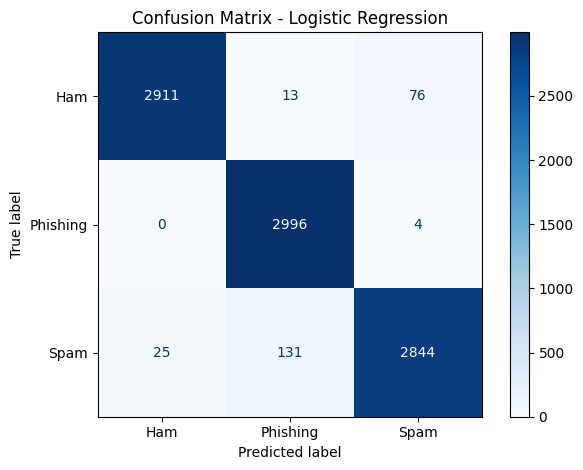


Confusion Matrix: Multinomial Naive Bayes


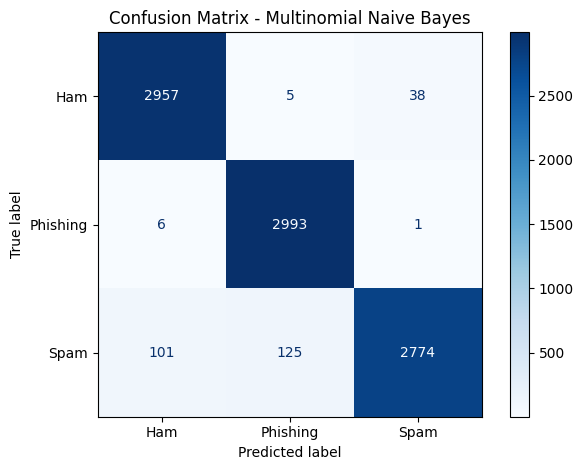


Confusion Matrix: Linear SVM


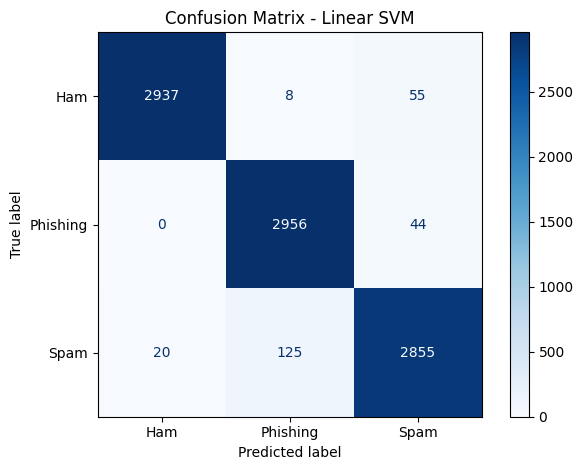

In [32]:

# STEP 9: Confusion Matrices

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

class_names = ["Ham", "Phishing", "Spam"]

for name, model in trained_models.items():

    y_pred = model.predict(X_test_tfidf)

    print("\nConfusion Matrix:", name)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=[0, 1, 2],
        display_labels=class_names,
        cmap="Blues",
        values_format="d"
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.tight_layout()
    plt.show()


In [33]:

# STEP 10: Save the selected Email Analysis model

import joblib
import os

# Create a directory for model files
os.makedirs("email_analysis_model", exist_ok=True)

# Save Logistic Regression model
joblib.dump(
    trained_models["Logistic Regression"],
    "email_analysis_model/logistic_regression_model.pkl"
)

# Save TF-IDF vectorizer
joblib.dump(
    tfidf_vectorizer,
    "email_analysis_model/tfidf_vectorizer.pkl"
)

print("Model saved successfully!")
print("TF-IDF vectorizer saved successfully!")

# List saved files
print("\nSaved model files:")

for file in os.listdir("email_analysis_model"):
    print(file)


Model saved successfully!
TF-IDF vectorizer saved successfully!

Saved model files:
logistic_regression_model.pkl
tfidf_vectorizer.pkl


In [36]:
import joblib

model = joblib.load(
    "email_analysis_model/logistic_regression_model.pkl"
)

vectorizer = joblib.load(
    "email_analysis_model/tfidf_vectorizer.pkl"
)

print("Model loaded successfully!")
print("Vectorizer loaded successfully!")

Model loaded successfully!
Vectorizer loaded successfully!


In [37]:
sample_emails = [
    """


Skip to content
Using Gmail with screen readers
Enable desktop notifications for Gmail.
   OK  No thanks
32 of 1,324
MongoDB high availability, custom headers for project webhooks, MySQL PITR
Inbox

Railway <hello@news.railway.app>
Sat, Oct 3, 1:59 AM
to me

Railway	PRODUCT UPDATE
Changelog time!
It's Friday and you know what that means! Here's a summary of the stuff we shipped this week:

•MongoDB high availability
•Custom headers for project webhooks
•MySQL point-in-time recovery
•Fixes and improvements
Read the changelog
If you have any thoughts/feedback on the changes we’re making, reach out on Central Station!

- Your friends at Railway

Central Station | X/Twitter | LinkedIn | YouTube

© 2026 Railway Corp. All rights reserved.	Unsubscribe

    """
]

label_names = {
    0: "Safe",
    1: "Malicious",
    2: "Suspicious"
}

for i, email in enumerate(sample_emails, start=1):

    email_tfidf = vectorizer.transform([email])

    prediction = model.predict(email_tfidf)[0]

    probabilities = model.predict_proba(email_tfidf)[0]

    print(f"\nEmail {i}")
    print("-" * 40)

    print("Predicted class:", label_names[prediction])

    print("Class probabilities:")

    for label, probability in zip(model.classes_, probabilities):
        print(f"{label_names[label]}: {probability * 100:.2f}%")


Email 1
----------------------------------------
Predicted class: Safe
Class probabilities:
Safe: 75.09%
Malicious: 0.21%
Suspicious: 24.69%


In [38]:
import joblib
import json

# Load the trained model and TF-IDF vectorizer
model = joblib.load(
    "email_analysis_model/logistic_regression_model.pkl"
)

vectorizer = joblib.load(
    "email_analysis_model/tfidf_vectorizer.pkl"
)

# Map dataset labels to final classifications
classification_mapping = {
    0: "safe",
    1: "malicious",
    2: "suspicious"
}

print("Email Analysis Agent initialized successfully!")

Email Analysis Agent initialized successfully!


In [39]:
def analyze_email(email_text):

    try:
        # Check email input
        if not email_text or not email_text.strip():
            raise ValueError("Email content cannot be empty.")

        # Convert email into TF-IDF features
        email_tfidf = vectorizer.transform([email_text])

        # Predict email class
        prediction = int(model.predict(email_tfidf)[0])

        # Get class probabilities
        probabilities = model.predict_proba(email_tfidf)[0]

        # Map prediction to final classification
        classification = classification_mapping[prediction]

        # Get predicted class probability
        predicted_probability = float(
            probabilities[list(model.classes_).index(prediction)]
        )

        # Generate explanation
        label_names = {
            0: "Ham (Legitimate)",
            1: "Phishing",
            2: "Spam"
        }

        explanation = (
            f"The model classified this email as "
            f"{label_names[prediction]} with "
            f"{predicted_probability * 100:.2f}% probability."
        )

        # Generate structured agent result
        result = {
            "agent": "Email Analysis Agent",
            "status": "completed",
            "classification": classification,
            "risk_score": None,
            "indicators": [],
            "explanation": explanation,
            "evidence": []
        }

        return result

    except Exception as e:

        return {
            "agent": "Email Analysis Agent",
            "status": "error",
            "classification": "unknown",
            "risk_score": None,
            "indicators": [],
            "explanation": str(e),
            "evidence": []
        }

In [40]:
sample_email = """
Dear Customer,

Your bank account will be suspended today.
Click the link below immediately and verify your password.

Thank you,
Bank Security Team
"""

result = analyze_email(sample_email)

print(json.dumps(result, indent=4))

{
    "agent": "Email Analysis Agent",
    "status": "completed",
    "classification": "suspicious",
    "risk_score": null,
    "indicators": [],
    "explanation": "The model classified this email as Spam with 77.82% probability.",
    "evidence": []
}


In [41]:
import re

def analyze_email_content(email_text):

    indicators = []
    evidence = []

    # Suspicious patterns
    patterns = {
        "Urgent language": [
            r"\bimmediately\b",
            r"\burgent\b",
            r"\bact now\b",
            r"\bwithin 24 hours\b",
            r"\bas soon as possible\b"
        ],

        "Account suspension warning": [
            r"\baccount.{0,30}(suspend|blocked|disabled)\b",
            r"\b(suspend|blocked|disabled).{0,30}account\b"
        ],

        "Credential request": [
            r"\b(password|login credentials|passcode)\b",
            r"\bverify.{0,30}(account|password|identity)\b"
        ],

        "Suspicious link instruction": [
            r"\b(click|follow|visit).{0,40}(link|url|below)\b"
        ],

        "Financial information request": [
            r"\b(bank details|credit card|card number|bank account details)\b"
        ]
    }

    # Detect patterns
    for indicator, expressions in patterns.items():

        for expression in expressions:

            matches = re.finditer(
                expression,
                email_text,
                re.IGNORECASE
            )

            for match in matches:

                indicators.append(indicator)
                evidence.append(match.group().strip())

                break

            if indicator in indicators:
                break

    return {
        "indicators": list(dict.fromkeys(indicators)),
        "evidence": list(dict.fromkeys(evidence))
    }

In [42]:
content_result = analyze_email_content(sample_email)

print(json.dumps(content_result, indent=4))

{
    "indicators": [
        "Urgent language",
        "Credential request",
        "Suspicious link instruction"
    ],
    "evidence": [
        "immediately",
        "password",
        "Click the link below"
    ]
}


In [43]:
import json

def analyze_email(email_text):

    try:
        if not email_text or not email_text.strip():
            raise ValueError("Email content cannot be empty.")

        # 1. Machine Learning Analysis
        email_tfidf = vectorizer.transform([email_text])

        prediction = int(model.predict(email_tfidf)[0])

        probabilities = model.predict_proba(email_tfidf)[0]

        classification_mapping = {
            0: "safe",
            1: "malicious",
            2: "suspicious"
        }

        label_names = {
            0: "Ham (Legitimate)",
            1: "Phishing",
            2: "Spam"
        }

        classification = classification_mapping[prediction]

        predicted_probability = float(
            probabilities[list(model.classes_).index(prediction)]
        )

        # 2. Rule-Based Content Analysis
        content_result = analyze_email_content(email_text)

        indicators = content_result["indicators"]
        evidence = content_result["evidence"]

        # 3. Generate Explanation
        explanation = (
            f"The machine learning model classified the email as "
            f"{label_names[prediction]} with "
            f"{predicted_probability * 100:.2f}% probability. "
            f"Content analysis detected {len(indicators)} "
            f"suspicious indicators."
        )

        # 4. Generate Final Agent Result
        result = {
            "agent": "Email Analysis Agent",
            "status": "completed",
            "classification": classification,
            "risk_score": None,
            "indicators": indicators,
            "explanation": explanation,
            "evidence": evidence
        }

        return result

    except Exception as e:

        return {
            "agent": "Email Analysis Agent",
            "status": "error",
            "classification": "unknown",
            "risk_score": None,
            "indicators": [],
            "explanation": str(e),
            "evidence": []
        }

In [44]:
result = analyze_email(sample_email)

print(json.dumps(result, indent=4))

{
    "agent": "Email Analysis Agent",
    "status": "completed",
    "classification": "suspicious",
    "risk_score": null,
    "indicators": [
        "Urgent language",
        "Credential request",
        "Suspicious link instruction"
    ],
    "explanation": "The machine learning model classified the email as Spam with 77.82% probability. Content analysis detected 3 suspicious indicators.",
    "evidence": [
        "immediately",
        "password",
        "Click the link below"
    ]
}


In [45]:
print("Dataset columns:")
print(df.columns.tolist())

Dataset columns:
['text', 'label', 'text_length']


In [46]:
print("Cleaned dataset columns:")
print(cleaned_df.columns.tolist())

Cleaned dataset columns:
['text', 'label']


In [47]:
print(cleaned_df["text"].iloc[0])

downloadable software http cabins jetlow com a man paints with his brains and not with his hands we can always take but never give girls just want to have funds 


In [48]:
import re

def analyze_email_content(email_text):

    indicators = []
    evidence = []

    # Define suspicious patterns
    patterns = {
        "Urgent language": [
            r"\bimmediately\b",
            r"\burgent\b",
            r"\bact now\b",
            r"\bwithin 24 hours\b",
            r"\bas soon as possible\b",
            r"\bwithout delay\b"
        ],

        "Account suspension warning": [
            r"\baccount\b.{0,60}\b(suspend|suspended|blocked|disabled|locked)\b",
            r"\b(suspend|suspended|blocked|disabled|locked)\b.{0,60}\baccount\b"
        ],

        "Credential request": [
            r"\b(password|login credentials|passcode|OTP)\b",
            r"\bverify\b.{0,60}\b(account|password|identity|credentials)\b"
        ],

        "Suspicious link instruction": [
            r"\b(click|follow|visit|open)\b.{0,60}\b(link|URL|website|below)\b"
        ],

        "Financial information request": [
            r"\b(bank details|credit card|card number|bank account details)\b"
        ]
    }

    # Split email into sentences
    sentences = re.split(r'(?<=[.!?])\s+', email_text)

    for indicator, expressions in patterns.items():

        for expression in expressions:

            for sentence in sentences:

                if re.search(expression, sentence, re.IGNORECASE):

                    indicators.append(indicator)
                    evidence.append(sentence.strip())

                    break

            if indicator in indicators:
                break

    return {
        "indicators": list(dict.fromkeys(indicators)),
        "evidence": list(dict.fromkeys(evidence))
    }

In [49]:
content_result = analyze_email_content(sample_email)

print(json.dumps(content_result, indent=4))

{
    "indicators": [
        "Urgent language",
        "Account suspension warning",
        "Credential request",
        "Suspicious link instruction"
    ],
    "evidence": [
        "Click the link below immediately and verify your password.",
        "Dear Customer,\n\nYour bank account will be suspended today."
    ]
}


In [50]:
result = analyze_email(sample_email)

print(json.dumps(result, indent=4))

{
    "agent": "Email Analysis Agent",
    "status": "completed",
    "classification": "suspicious",
    "risk_score": null,
    "indicators": [
        "Urgent language",
        "Account suspension warning",
        "Credential request",
        "Suspicious link instruction"
    ],
    "explanation": "The machine learning model classified the email as Spam with 77.82% probability. Content analysis detected 4 suspicious indicators.",
    "evidence": [
        "Click the link below immediately and verify your password.",
        "Dear Customer,\n\nYour bank account will be suspended today."
    ]
}


In [51]:
email_data = {
    "sender": "security@example-bank.com",
    "subject": "URGENT: Verify your account immediately",
    "body": sample_email
}

print(email_data)

{'sender': 'security@example-bank.com', 'subject': 'URGENT: Verify your account immediately', 'body': '\nDear Customer,\n\nYour bank account will be suspended today.\nClick the link below immediately and verify your password.\n\nThank you,\nBank Security Team\n'}


In [52]:
import re

def analyze_email_subject(subject):

    indicators = []
    evidence = []

    subject_patterns = {
        "Urgent subject line": [
            r"\burgent\b",
            r"\bimmediately\b",
            r"\bact now\b",
            r"\bimportant action required\b"
        ],

        "Account warning in subject": [
            r"\baccount\b.{0,50}\b(suspend|suspended|blocked|locked|verify)\b"
        ],

        "Sensitive information request": [
            r"\b(password|credentials|OTP|verify your identity)\b"
        ],

        "Unusual financial notification": [
            r"\b(payment|bank|invoice|refund|transaction)\b"
        ]
    }

    for indicator, patterns in subject_patterns.items():

        for pattern in patterns:

            if re.search(pattern, subject, re.IGNORECASE):

                indicators.append(indicator)
                evidence.append(subject.strip())
                break

    return {
        "indicators": list(dict.fromkeys(indicators)),
        "evidence": list(dict.fromkeys(evidence))
    }

In [53]:
subject_result = analyze_email_subject(email_data["subject"])

print(json.dumps(subject_result, indent=4))

{
    "indicators": [
        "Urgent subject line"
    ],
    "evidence": [
        "URGENT: Verify your account immediately"
    ]
}


In [69]:
import re

def analyze_email_sender(sender):

    indicators = []
    evidence = []

    sender = sender.strip()

    email_pattern = r"^[^@\s]+@[^@\s]+\.[^@\s]+$"

    if not re.match(email_pattern, sender):

        indicators.append(
            "Invalid or malformed sender address"
        )

        evidence.append(
            f"Sender address: {sender}"
        )

    else:

        local_part, domain = sender.rsplit("@", 1)

        if domain.count(".") > 3:

            indicators.append(
                "Unusually complex sender domain"
            )

            evidence.append(
                f"Sender domain: {domain}"
            )

    return {
        "indicators": list(dict.fromkeys(indicators)),
        "evidence": list(dict.fromkeys(evidence))
    }

In [70]:
sender_result = analyze_email_sender(email_data["sender"])

print(json.dumps(sender_result, indent=4))

{
    "indicators": [],
    "evidence": []
}


In [75]:
def analyze_complete_email(email_data):

    try:
        sender = email_data.get("sender", "")
        subject = email_data.get("subject", "")
        body = email_data.get("body", "")

        if not body.strip():
            raise ValueError("Email body cannot be empty.")

        # 1. Machine Learning Classification
        email_tfidf = vectorizer.transform([body])

        prediction = int(model.predict(email_tfidf)[0])
        probabilities = model.predict_proba(email_tfidf)[0]

        classification_mapping = {
            0: "safe",
            1: "malicious",
            2: "suspicious"
        }

        label_names = {
            0: "Ham (Legitimate)",
            1: "Phishing",
            2: "Spam"
        }

        classification = classification_mapping[prediction]

        predicted_probability = float(
            probabilities[list(model.classes_).index(prediction)]
        )

        # 2. Body Analysis
        body_result = analyze_email_content(body)

        # 3. Subject Analysis
        subject_result = analyze_email_subject(subject)

        # 4. Sender Analysis
        sender_result = analyze_email_sender(sender)

        # 5. Combine indicators and evidence
        indicators = (
            body_result["indicators"]
            + subject_result["indicators"]
            + sender_result["indicators"]
        )

        evidence = (
            body_result["evidence"]
            + subject_result["evidence"]
            + sender_result["evidence"]
        )

        indicators = list(dict.fromkeys(indicators))
        evidence = list(dict.fromkeys(evidence))

        # 6. Generate explanation
        explanation = (
            f"The machine learning model classified the email as "
            f"{label_names[prediction]} with "
            f"{predicted_probability * 100:.2f}% probability. "
            f"Email analysis detected {len(indicators)} indicators."
        )

        # 7. Generate final result
        result = {
            "agent": "Email Analysis Agent",
            "status": "completed",
            "classification": classification,
            "risk_score": None,
            "indicators": indicators,
            "explanation": explanation,
            "evidence": evidence
        }

        return result

    except Exception as e:

        return {
            "agent": "Email Analysis Agent",
            "status": "error",
            "classification": "unknown",
            "risk_score": None,
            "indicators": [],
            "explanation": str(e),
            "evidence": []
        }

In [76]:
result = analyze_complete_email(email_data)

print(json.dumps(result, indent=4))

{
    "agent": "Email Analysis Agent",
    "status": "completed",
    "classification": "suspicious",
    "risk_score": null,
    "indicators": [
        "Urgent language",
        "Account suspension warning",
        "Credential request",
        "Suspicious link instruction",
        "Urgent subject line"
    ],
    "explanation": "The machine learning model classified the email as Spam with 77.82% probability. Email analysis detected 5 indicators.",
    "evidence": [
        "Click the link below immediately and verify your password.",
        "Dear Customer,\n\nYour bank account will be suspended today.",
        "URGENT: Verify your account immediately"
    ]
}


In [60]:
test_emails = [
    {
        "sender": "colleague@gmail.com",
        "subject": "Meeting schedule for tomorrow",
        "body": """
        Hello,

        Our meeting is scheduled for tomorrow at 10 AM.
        Please review the attached meeting notes.

        Best regards,
        John
        """
    },

    {
        "sender": "security@example-bank.com",
        "subject": "URGENT: Verify your account immediately",
        "body": """
        Dear Customer,

        Your bank account will be suspended today.
        Click the link below immediately and verify your password.

        Thank you,
        Bank Security Team
        """
    },

    {
        "sender": "offers@example.com",
        "subject": "Special discount offer",
        "body": """
        Congratulations!

        Get 50 percent off on our products.
        Subscribe to our newsletter to receive more offers.
        """
    }
]

for i, email in enumerate(test_emails, start=1):

    print(f"\n========== EMAIL {i} ==========")

    result = analyze_complete_email(email)

    print(json.dumps(result, indent=4))


========== EMAIL 1 ==========
{
    "agent": "Email Analysis Agent",
    "status": "completed",
    "classification": "safe",
    "risk_score": null,
    "indicators": [
        "Free email provider used"
    ],
    "explanation": "The machine learning model classified the email as Ham (Legitimate) with 94.43% probability. Email analysis detected 1 indicators.",
    "evidence": [
        "Sender domain: gmail.com"
    ]
}

========== EMAIL 2 ==========
{
    "agent": "Email Analysis Agent",
    "status": "completed",
    "classification": "suspicious",
    "risk_score": null,
    "indicators": [
        "Urgent language",
        "Account suspension warning",
        "Credential request",
        "Suspicious link instruction",
        "Urgent subject line"
    ],
    "explanation": "The machine learning model classified the email as Spam with 77.82% probability. Email analysis detected 5 indicators.",
    "evidence": [
        "Click the link below immediately and verify your password

In [74]:
import inspect
import json

print("CURRENT SENDER FUNCTION:")
print(inspect.getsource(analyze_email_sender))

print("\nDIRECT SENDER TEST:")
sender_result = analyze_email_sender("colleague@gmail.com")

print(json.dumps(sender_result, indent=4))

CURRENT SENDER FUNCTION:
def analyze_email_sender(sender):

    indicators = []
    evidence = []

    sender = sender.strip()

    email_pattern = r"^[^@\s]+@[^@\s]+\.[^@\s]+$"

    if not re.match(email_pattern, sender):

        indicators.append(
            "Invalid or malformed sender address"
        )

        evidence.append(
            f"Sender address: {sender}"
        )

    else:

        local_part, domain = sender.rsplit("@", 1)

        if domain.count(".") > 3:

            indicators.append(
                "Unusually complex sender domain"
            )

            evidence.append(
                f"Sender domain: {domain}"
            )

    return {
        "indicators": list(dict.fromkeys(indicators)),
        "evidence": list(dict.fromkeys(evidence))
    }


DIRECT SENDER TEST:
{
    "indicators": [],
    "evidence": []
}


In [77]:
email1_result = analyze_complete_email(test_emails[0])

print(json.dumps(email1_result, indent=4))

{
    "agent": "Email Analysis Agent",
    "status": "completed",
    "classification": "safe",
    "risk_score": null,
    "indicators": [],
    "explanation": "The machine learning model classified the email as Ham (Legitimate) with 94.43% probability. Email analysis detected 0 indicators.",
    "evidence": []
}
